<a href="https://colab.research.google.com/github/Decoding-Data-Science/CommunityWorkshops/blob/main/bootcampoct26/notebooks/DDS_HR_Data_Understanding.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DDS HR Data Understanding: Unstructured (PDFs) and Structured (Database)

**Decoding Data Science | CPD UK Bootcamp | Gemini HR Leave Assistant**

Before building a chatbot, you must understand the data it will use. This notebook looks at both kinds:

| Type | Files | What it holds | Used for |
|---|---|---|---|
| **Unstructured** | 4 PDFs (Handbook, Leave Policy, HR FAQ, Remote Work Policy) | Rules and explanations in free text | **RAG** (Day 2): answers "what is the rule?" |
| **Structured** | `dds_leave.db` (SQLite) | Employees and leave requests in tables | **SQL tool** (Day 3): answers "what is my balance?" |

**Sections**
1. Setup and upload
2. Unstructured data: read, profile and chunk the PDFs
3. Structured data: schema, quality checks and EDA
4. Putting both together: which question goes to which source
5. Summary

Run the cells from top to bottom.

## 1. Setup and upload

**Step 1.1** Install the libraries. Colab already has most of them; `pypdf` is the one we need to read PDFs.

In [ ]:
!pip install -q pypdf

**Step 1.2** Upload all 5 files in one go: the 4 PDFs and `dds_leave.db`.
In the file picker, select all 5 together (hold Ctrl or Cmd). If you prefer, drag them into the Files panel on the left of Colab instead and skip this cell's upload; the notebook then reads from the current folder.

In [ ]:
import os, re, sqlite3, collections
import pandas as pd
import matplotlib.pyplot as plt
from pypdf import PdfReader

pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 140)

try:
    from google.colab import files
    files.upload()                      # choose the 4 PDFs and dds_leave.db
except ImportError:
    print("Not running in Colab: reading files from the current folder.")

pdf_files = sorted(f for f in os.listdir(".") if f.lower().endswith(".pdf"))
db_file = "dds_leave.db"
print("PDFs found:", len(pdf_files))
for f in pdf_files: print("  -", f)
print("Database found:", os.path.exists(db_file))
assert pdf_files, "No PDFs found. Upload the 4 PDF files."
assert os.path.exists(db_file), "dds_leave.db not found. Upload it."

Saving DDS_Employee_Handbook_Synthetic_v1.pdf to DDS_Employee_Handbook_Synthetic_v1.pdf
Saving DDS_HR_FAQ_Synthetic_v1.pdf to DDS_HR_FAQ_Synthetic_v1.pdf
Saving DDS_Leave_Policy_v2.pdf to DDS_Leave_Policy_v2.pdf
Saving DDS_Remote_Work_Policy_Synthetic_v1.pdf to DDS_Remote_Work_Policy_Synthetic_v1.pdf
PDFs found: 4
  - DDS_Employee_Handbook_Synthetic_v1.pdf
  - DDS_HR_FAQ_Synthetic_v1.pdf
  - DDS_Leave_Policy_v2.pdf
  - DDS_Remote_Work_Policy_Synthetic_v1.pdf
Database found: True


## 2. Unstructured data: the PDFs

Unstructured means there are no rows and columns, only text. We cannot query it with SQL. To use it in a chatbot we first **read** it, **profile** it, then **split it into chunks** (Day 2).

### 2.1 Read every PDF
`PdfReader` opens a PDF; `extract_text()` returns the text of one page. We keep the text per page so we can cite page numbers later.

In [ ]:
docs = {}   # file name -> list of page texts
for f in pdf_files:
    reader = PdfReader(f)
    docs[f] = [(p.extract_text() or "") for p in reader.pages]

# Clean file names for display
short = lambda f: f.replace("DDS_", "").replace("_Synthetic_v1.pdf", "")
profile = pd.DataFrame({
    "document": [short(f) for f in docs],
    "pages": [len(p) for p in docs.values()],
    "words": [sum(len(t.split()) for t in p) for p in docs.values()],
    "characters": [sum(len(t) for t in p) for p in docs.values()],
})
profile["words_per_page"] = (profile["words"] / profile["pages"]).round(0)
profile

,document,pages,words,characters,words_per_page
0,Employee_Handbook,4,1172,7942,293.0
1,HR_FAQ,1,242,1559,242.0
2,Leave_Policy_v2.pdf,6,1927,11912,321.0
3,Remote_Work_Policy,2,458,3021,229.0


**Look at the numbers.** The Handbook is the largest document. The FAQ is the smallest. A real company would have far more text, but the same steps apply.

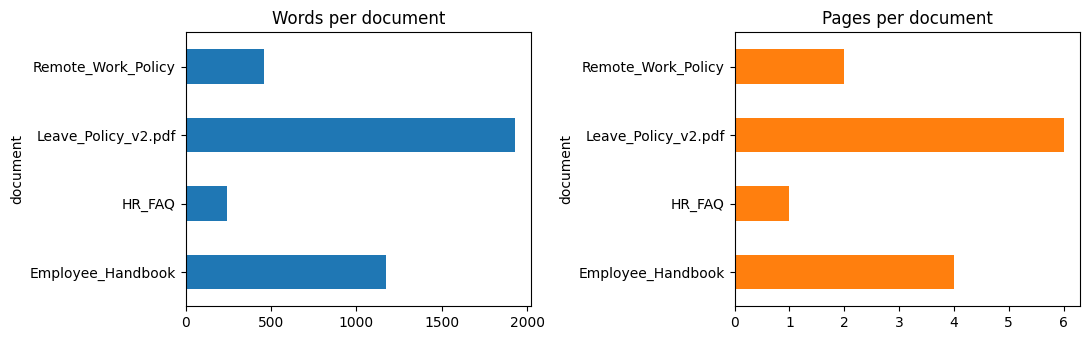

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
profile.set_index("document")["words"].plot.barh(ax=ax[0], title="Words per document")
profile.set_index("document")["pages"].plot.barh(ax=ax[1], title="Pages per document", color="tab:orange")
plt.tight_layout(); plt.show()

### 2.2 Read a sample page
Always read some raw text yourself. Check that the extraction is clean: no broken words, no garbage characters.

In [ ]:
sample = short(pdf_files[0])
print("Document:", sample, "| page 1\n")
print(docs[pdf_files[0]][0][:1200])

Document: Employee_Handbook | page 1

DDS Employee Handbook (Synthetic) v1
Effective date: March 03, 2026  Dubai (GST)
Note: This document is a synthetic, training-friendly employee handbook for demos, onboarding
simulations, and HR-policy chatbot prototypes. It is not legal advice and must be reviewed by qualified
counsel before any real-world use.
1. Welcome to Decoding Data Science (DDS)
DDS is a Dubai-based academy, consulting practice, and community focused on data science, AI, and
applied generative AI. We operate with a global mindset and a high trust culture—shipping practical
outcomes while supporting each other.
This handbook explains workplace expectations, benefits, and policies. If any local law conflicts with
this handbook, applicable law prevails.
2. Company Values & Ways of Working
 Build with clarity: define the user, problem, inputs/outputs, and definition of done.
 Bias for action: ship small, iterate fast, measure outcomes.
 Respect and inclusion: disagreement i

### 2.3 Find the structure (sections)
These policies use numbered headings such as `2. Annual Leave`. Section-aware splitting uses these headings, so we check how many we can detect in each document.

In [ ]:
heading_re = re.compile(r"(?m)^\s*(\d{1,2})\.\s+([A-Z].+)$")
rows = []
for f, pages in docs.items():
    full = "\n".join(pages)
    for num, title in heading_re.findall(full):
        rows.append({"document": short(f), "section": int(num), "heading": title.strip()[:55]})
sections = pd.DataFrame(rows)
print("Headings detected per document:")
print(sections.groupby("document").size())
sections[sections.document.str.contains("Leave")].head(15)

Headings detected per document:
document
Employee_Handbook      18
Leave_Policy_v2.pdf    12
Remote_Work_Policy      8
dtype: int64


,document,section,heading
18,Leave_Policy_v2.pdf,1,Leave Entitlements at a Glance
19,Leave_Policy_v2.pdf,2,Definitions
20,Leave_Policy_v2.pdf,3,Annual Leave
21,Leave_Policy_v2.pdf,4,"Carry-Over, Expiry and Encashment"
22,Leave_Policy_v2.pdf,5,Sick Leave
23,Leave_Policy_v2.pdf,6,Public Holidays
24,Leave_Policy_v2.pdf,7,"Maternity, Paternity and Parental Leave"
25,Leave_Policy_v2.pdf,8,Other Leave Types
26,Leave_Policy_v2.pdf,9,Religious Observance and Ramadan Working Hours
27,Leave_Policy_v2.pdf,10,How to Request Leave (Workflow)


Headings can be missed when the PDF puts a heading and its first sentence on the same line. That is normal. It is one reason we **test chunking strategies** on Day 2 instead of assuming one is right.

### 2.4 What are the documents about? (most frequent words)
A quick keyword count shows each document's focus. We remove common filler words first.

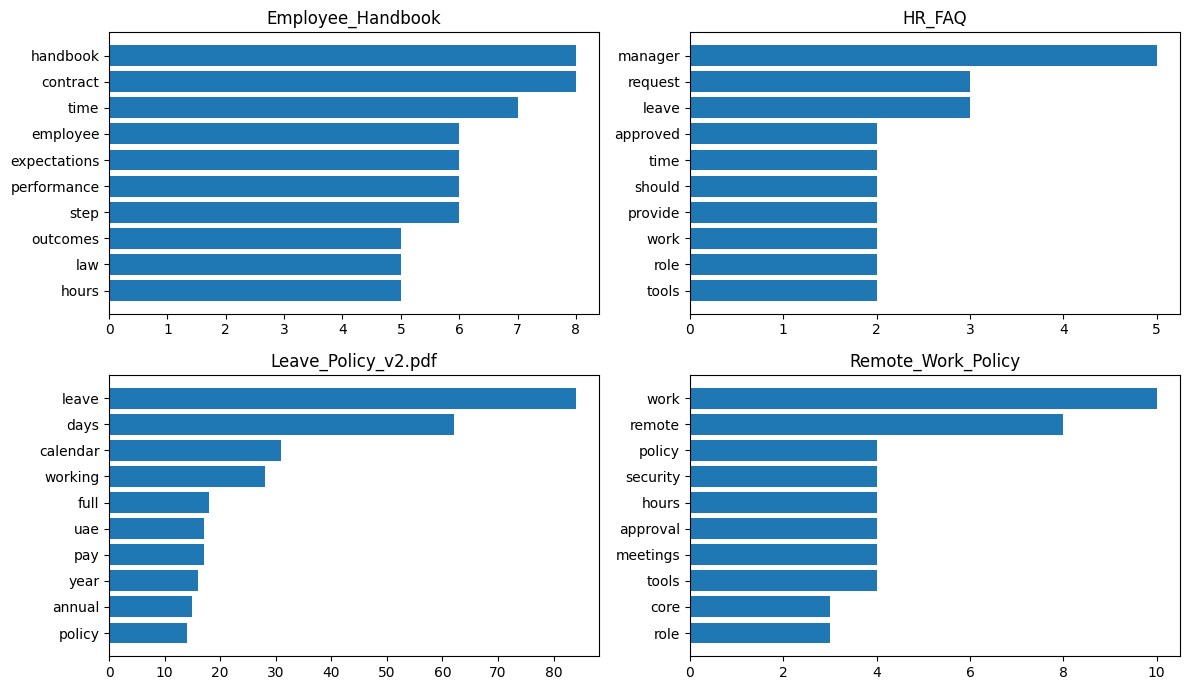

In [ ]:
stop = set("""the a an and or of to in for on with is are be as at by from that this it its if your you may must can will not
all any per who how what when where which than then their them they our we us has have had was were also into out up use used
dds synthetic decoding data science page internal demo v1 effective date dubai gst note document""".split())

def top_words(text, n=10):
    words = re.findall(r"[a-zA-Z]{3,}", text.lower())
    return collections.Counter(w for w in words if w not in stop).most_common(n)

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, (f, pages) in zip(axes.ravel(), docs.items()):
    tw = top_words("\n".join(pages))
    ax.barh([w for w, _ in tw][::-1], [c for _, c in tw][::-1])
    ax.set_title(short(f))
plt.tight_layout(); plt.show()

### 2.5 Preview chunking (what Day 2 is about)
A chatbot cannot read a whole handbook for every question. We cut the text into **chunks**, search for the most relevant chunks, and give only those to the model.
Two settings matter: **chunk size** (characters per chunk) and **overlap** (characters repeated between neighbours, so a rule is not cut in half).
Change the numbers below and watch the chunk count change.

In [ ]:
def make_chunks(text, size=1200, overlap=200):
    chunks, start = [], 0
    while start < len(text):
        chunks.append(text[start:start + size])
        start += size - overlap
    return chunks

CHUNK_SIZE, OVERLAP = 1200, 200      # <- try 400/50 and 2500/300
res = []
for f, pages in docs.items():
    ch = make_chunks("\n".join(pages), CHUNK_SIZE, OVERLAP)
    res.append({"document": short(f), "chunks": len(ch),
                "avg_chars": round(sum(len(c) for c in ch) / len(ch))})
pd.DataFrame(res)

,document,chunks,avg_chars
0,Employee_Handbook,8,1168
1,HR_FAQ,2,880
2,Leave_Policy_v2.pdf,12,1176
3,Remote_Work_Policy,4,861


In [ ]:
leave_file = next(f for f in docs if "Leave" in f)
ch = make_chunks("\n".join(docs[leave_file]), CHUNK_SIZE, OVERLAP)
i = min(1, len(ch) - 1)
print(f"Leave Policy has {len(ch)} chunks. Showing chunk {i + 1}:\n")
print(ch[i])

Leave Policy has 12 chunks. Showing chunk 2:

ll pay
Full pay (then
per §4.4)
Same day, within 1
hour of start time
Medical certificate for
2+ consecutive days
Maternity leave
60 calendar days
Full pay
30 calendar days
before expected
date
Medical
documentation
Paternity leave
5 working days, within 6
months of birth
Full pay
30 calendar days
where foreseeable
Birth certificate
Parental leave
(additional)
5 working days per parent,
within 6 months of birth
Full pay
14 calendar days
Birth certificate
Bereavement leave
5 working days
(spouse/child/parent); 3
working days
(sibling/grandparent)
Full pay
Notify as soon as
possible
May be requested
Marriage leave
3 working days (once during
employment)
Full pay
14 calendar days
Marriage certificate
Study leave
10 working days per year (2+
years of service, enrolled at
an accredited UAE institution)
Full pay
14 calendar days
Exam schedule /
enrollment proof
Hajj leave
Up to 30 calendar days (once
during employment)
Unpaid
60 calendar days
Non

**Takeaway for unstructured data:** text is read, profiled and split. It answers questions about **rules**: notice periods, who approves, what counts as misuse.

## 3. Structured data: the SQLite database

Structured means tables with rows and columns. We query it with SQL. It answers questions about **facts and numbers**: how many days does Aisha have left?

### 3.1 Connect and look at the schema
`sqlite_master` lists every table and view in the file.

In [ ]:
con = sqlite3.connect(db_file)
pd.read_sql("SELECT name, type FROM sqlite_master WHERE type IN ('table','view') ORDER BY type", con)

,name,type
0,employees,table
1,leave_requests,table
2,leave_balances,view


In [ ]:
for t in ["employees", "leave_requests"]:
    print(f"\nTable: {t}")
    display(pd.read_sql(f"PRAGMA table_info({t})", con)[["name", "type", "notnull", "pk"]])


Table: employees


,name,type,notnull,pk
0,employee_id,INTEGER,0,1
1,full_name,TEXT,1,0
2,email,TEXT,0,0
3,department,TEXT,1,0
4,job_title,TEXT,1,0
5,manager_id,INTEGER,0,0
6,employment_type,TEXT,1,0
7,location,TEXT,1,0
8,hire_date,DATE,1,0
9,annual_entitlement,INTEGER,1,0



Table: leave_requests


,name,type,notnull,pk
0,request_id,INTEGER,0,1
1,employee_id,INTEGER,1,0
2,leave_type,TEXT,1,0
3,start_date,DATE,1,0
4,end_date,DATE,1,0
5,working_days,INTEGER,1,0
6,status,TEXT,1,0
7,submitted_on,DATE,1,0
8,approved_by,INTEGER,0,0
9,notes,TEXT,0,0


- `employees`: one row per person (100 rows).
- `leave_requests`: one row per request. `employee_id` links back to `employees` (a **foreign key**).
- `leave_balances`: a **view**, a saved query that works out used and remaining days from the requests.

### 3.2 Load the tables into pandas and look at them

In [ ]:
employees = pd.read_sql("SELECT * FROM employees", con, parse_dates=["hire_date"])
requests  = pd.read_sql("SELECT * FROM leave_requests", con, parse_dates=["start_date", "end_date", "submitted_on"])
balances  = pd.read_sql("SELECT * FROM leave_balances", con)
print("employees:", employees.shape, "| leave_requests:", requests.shape, "| leave_balances:", balances.shape)
employees.head()

employees: (100, 10) | leave_requests: (518, 10) | leave_balances: (100, 8)


,employee_id,full_name,email,department,job_title,manager_id,employment_type,location,hire_date,annual_entitlement
0,1,Aisha Khan,aisha.khan@decodingdatascience.com,Academy & Training,Instructor,NaN,Full-time,Dubai HQ,2023-02-13,25
1,2,John Doe,john.doe@decodingdatascience.com,Consulting,AI Consultant,34.0,Full-time,Dubai HQ,2025-04-07,22
2,3,Emma Tanaka,emma.tanaka@decodingdatascience.com,Sales & Partnerships,Partnerships Manager,26.0,Full-time,Dubai HQ,2024-10-15,25
3,4,Kavya Iyer,kavya.iyer@decodingdatascience.com,Community & Marketing,Content Specialist,30.0,Full-time,Dubai HQ,2021-05-29,30
4,5,Meera Khoury,meera.khoury@decodingdatascience.com,Sales & Partnerships,Partnerships Manager,31.0,Full-time,Dubai HQ,2021-02-01,30


In [ ]:
requests.head()

### 3.3 Data quality checks
Never trust data before you check it. We look for missing values, duplicates, impossible dates and broken links between tables.

In [ ]:
checks = {
    "duplicate employee_id": int(employees.employee_id.duplicated().sum()),
    "duplicate emails": int(employees.email.duplicated().sum()),
    "requests with end before start": int((requests.end_date < requests.start_date).sum()),
    "requests with unknown employee": int((~requests.employee_id.isin(employees.employee_id)).sum()),
    "working_days <= 0": int((requests.working_days <= 0).sum()),
    "approved requests without approver": int(((requests.status == "Approved") & requests.approved_by.isna()).sum()),
}
pd.Series(checks, name="issues found").to_frame()

In [ ]:
print("Missing values per column (requests):")
requests.isna().sum()

Missing `approved_by` for Pending requests and empty `notes` are **expected**, not errors. Always ask whether a missing value is a problem or just how the process works.

### 3.4 Exploratory analysis (EDA)
**Who works here?**

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
employees.department.value_counts().sort_values().plot.barh(ax=ax[0], title="Employees per department")
employees.annual_entitlement.value_counts().sort_index().plot.bar(ax=ax[1], title="Annual entitlement (days)", rot=0)
plt.tight_layout(); plt.show()

**What kind of leave do people take?**

In [ ]:
by_type = requests.groupby("leave_type").agg(requests=("request_id", "count"),
                                              total_days=("working_days", "sum"),
                                              avg_days=("working_days", "mean")).round(1)
display(by_type)
display(requests.status.value_counts().to_frame("requests"))

**When do people take annual leave?** Look for peaks. Policy section on peak periods says approvals may be restricted then.

In [ ]:
annual = requests[(requests.leave_type == "Annual") & (requests.status == "Approved")].copy()
annual["month"] = annual.start_date.dt.to_period("M").astype(str)
annual.groupby("month").working_days.sum().plot.bar(figsize=(10, 3.5), title="Approved annual leave days by start month")
plt.tight_layout(); plt.show()

**How much leave is left?** The `leave_balances` view does the arithmetic for us.

In [ ]:
print(balances.annual_remaining.describe().round(1))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
balances.annual_remaining.plot.hist(bins=12, ax=ax[0], title="Annual days remaining (all employees)")
balances.groupby("department").annual_used.mean().sort_values().plot.barh(ax=ax[1], title="Average annual days used by department")
plt.tight_layout(); plt.show()

In [ ]:
print("Lowest balances (people close to running out):")
balances.nsmallest(5, "annual_remaining")[["full_name", "department", "annual_entitlement", "annual_used", "annual_remaining"]]

### 3.5 The same questions in SQL
Pandas is one way. SQL is what the Day 3 chatbot tool will run.

In [ ]:
q = """
SELECT department, COUNT(*) AS people, ROUND(AVG(annual_remaining),1) AS avg_days_left
FROM leave_balances GROUP BY department ORDER BY avg_days_left
"""
pd.read_sql(q, con)

In [ ]:
# A single employee's balance: exactly what a chatbot tool would ask
name = "Aisha Khan"
pd.read_sql("SELECT full_name, annual_entitlement, annual_used, annual_remaining, annual_pending FROM leave_balances WHERE full_name = ?", con, params=(name,))

In [ ]:
pd.read_sql("""SELECT leave_type, start_date, end_date, working_days, status
FROM leave_requests r JOIN employees e USING(employee_id)
WHERE e.full_name = 'John Doe' ORDER BY start_date""", con)

**Takeaway for structured data:** it answers questions about **numbers for one person or one group**. SQL does the exact arithmetic. A language model should never guess these.

## 4. Putting both together

The two sources do different jobs. A good assistant routes each question to the right one, or uses both.

| Question | Source | Why |
|---|---|---|
| How many days notice do I need for annual leave? | PDF (RAG) | A rule in the policy |
| Who approves my leave? | PDF (RAG) | A rule in the policy |
| How many annual days does Aisha Khan have left? | Database (SQL) | A personal number |
| Show John Doe's leave requests | Database (SQL) | Personal records |
| Can Aisha take 12 days? | **Both** | Database: 2 days left. Policy: approval rules |
| What is the probation period? | Neither may answer | Check whether the policy covers it. If not, the bot must say so |

**Consistency check.** If the policy and the database disagree, the chatbot will contradict itself. Compare what the Leave Policy says about entitlement with what is stored in the database.

In [ ]:
leave_text = "\n".join(docs[leave_file])
print("Policy lines about entitlement:")
for line in leave_text.splitlines():
    if "ntitlement" in line: print("  -", line.strip())
print("\nEntitlements stored in the database (days):", sorted(employees.annual_entitlement.unique().tolist()))
print("Employees per entitlement:", employees.annual_entitlement.value_counts().sort_index().to_dict())

The policy gives a **range** and says the exact number comes from the contract. The database stores the exact number per person. They agree, and that is what we want.

In [ ]:
con.close()

## 5. Summary: what we learned

**Unstructured (4 PDFs)**
- Read with `pypdf`, page by page.
- Profiled by pages, words and keywords.
- Structure found through numbered headings.
- Next step: chunk, embed, search (Day 2, RAG).

**Structured (`dds_leave.db`)**
- 100 employees, one Dubai office, plus their leave requests, plus a `leave_balances` view.
- Passed integrity checks; missing values are expected.
- Leave is mostly annual (about three quarters of requests), then sick.
- Next step: wrap SQL queries as tools for the agent (Day 3).

**The key idea:** rules live in documents, numbers live in databases. Understanding each kind of data first tells you which tool to build.

**Practice**
1. Change `CHUNK_SIZE` to 400 and then 2500. How does the chunk count change?
2. Find the employee with the most sick days taken.
3. Write a SQL query for how many requests each department has Pending.
4. Which PDF would answer "how do I report harassment?"